In [1]:
%pip install -U pandas numpy scikit-learn matplotlib seaborn openpyxl xlrd datasets transformers accelerate tf-keras

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

print("All libraries imported successfully!")

c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


In [3]:
import sys
print(sys.executable)

c:\Users\rayha\AppData\Local\Programs\Python\Python311\python.exe


In [4]:
%pip uninstall -y torchaudio

Found existing installation: torchaudio 2.5.1+cu121
Uninstalling torchaudio-2.5.1+cu121:
  Successfully uninstalled torchaudio-2.5.1+cu121
Note: you may need to restart the kernel to use updated packages.


In [3]:
if torch.cuda.is_available():

    device = torch.device("cuda")

    print("GPU is available!")
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

else:

    device = torch.device("cpu")

    print("GPU is NOT available.")
    print("Training will use CPU.")

print("\nUsing device:", device)

GPU is NOT available.
Training will use CPU.

Using device: cpu


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [5]:
DATA_PATH = "DS_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET LOADED")
print("=" * 60)

print("Shape:", df.shape)

display(df.head())

DATASET LOADED
Shape: (3150, 4)


,Sentence,Language,Intent,Split
0,"book a table in Montenegro for alissa, corneli...",english,bookrestaurant,train
1,"মন্টিনিগ্রোর অস্টেরিয়াতে অ্যালিসা, কর্নেলিয়া...",bangla,bookrestaurant,train
2,"Montenegro er osteria te alissa, cornelia will...",codemixed,bookrestaurant,train
3,I wanna listen to Electroclash,english,playmusic,train
4,আমি ইলেক্ট্রোক্ল্যাশ শুনতে চাই।,bangla,playmusic,train


In [6]:
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of samples:", len(df))
print("Number of intents:", df["Intent"].nunique())
print("Number of languages:", df["Language"].nunique())

DATASET INFORMATION
Columns:
['Sentence', 'Language', 'Intent', 'Split']

Missing values:
Sentence    0
Language    0
Intent      0
Split       0
dtype: int64

Number of samples: 3150
Number of intents: 7
Number of languages: 3


In [7]:
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
)

df["Sentence"] = (
    df["Sentence"]
    .astype(str)
    .str.strip()
)

df["Language"] = (
    df["Language"]
    .astype(str)
    .str.strip()
)

df["Intent"] = (
    df["Intent"]
    .astype(str)
    .str.strip()
)

df["Split"] = (
    df["Split"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print("Dataset cleaned successfully!")

Dataset cleaned successfully!


In [8]:
split_mapping = {
    "train": "train",
    "training": "train",

    "validation": "validation",
    "valid": "validation",
    "val": "validation",

    "test": "test",
    "testing": "test"
}

df["Split"] = df["Split"].map(split_mapping)

if df["Split"].isna().any():

    print("Invalid split values found:")
    display(df[df["Split"].isna()])

    raise ValueError("Invalid Split values found.")

print(df["Split"].value_counts())

Split
train         1908
validation     642
test           600
Name: count, dtype: int64


In [9]:
train_df = df[df["Split"] == "train"].copy()

val_df = df[df["Split"] == "validation"].copy()

test_df = df[df["Split"] == "test"].copy()

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training samples   :", len(train_df))
print("Validation samples :", len(val_df))
print("Test samples       :", len(test_df))
print("Total samples      :", len(train_df) + len(val_df) + len(test_df))

DATASET SPLIT
Training samples   : 1908
Validation samples : 642
Test samples       : 600
Total samples      : 3150


In [10]:
label_encoder = LabelEncoder()

label_encoder.fit(df["Intent"])

num_labels = len(label_encoder.classes_)

train_df["label"] = label_encoder.transform(
    train_df["Intent"]
)

val_df["label"] = label_encoder.transform(
    val_df["Intent"]
)

test_df["label"] = label_encoder.transform(
    test_df["Intent"]
)

id2label = {
    i: label
    for i, label in enumerate(label_encoder.classes_)
}

label2id = {
    label: i
    for i, label in id2label.items()
}

print("=" * 60)
print("LABEL INFORMATION")
print("=" * 60)

print("Number of intent classes:", num_labels)

print("\nLabel mapping:")
print(id2label)

LABEL INFORMATION
Number of intent classes: 7

Label mapping:
{0: 'addtoplaylist', 1: 'bookrestaurant', 2: 'getweather', 3: 'playmusic', 4: 'ratebook', 5: 'searchcreativework', 6: 'searchscreeningevent'}


In [11]:
train_dataset = Dataset.from_pandas(
    train_df[["Sentence", "label"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["Sentence", "label"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[["Sentence", "label"]],
    preserve_index=False
)

print("Datasets created successfully!")

print("\nTrain:", train_dataset)
print("Validation:", val_dataset)
print("Test:", test_dataset)

Datasets created successfully!

Train: Dataset({
    features: ['Sentence', 'label'],
    num_rows: 1908
})
Validation: Dataset({
    features: ['Sentence', 'label'],
    num_rows: 642
})
Test: Dataset({
    features: ['Sentence', 'label'],
    num_rows: 600
})


In [12]:
def compute_metrics(eval_prediction):

    logits = eval_prediction.predictions
    labels = eval_prediction.label_ids

    predictions = np.argmax(
        logits,
        axis=-1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }

In [13]:
MAX_LENGTH = 128

print("Maximum sequence length:", MAX_LENGTH)

Maximum sequence length: 128


In [14]:
DISTILBERT_NAME = "distilbert-base-multilingual-cased"

print("=" * 60)
print("LOADING MODEL")
print("=" * 60)

print("Model: DistilBERT")
print("Model name:", DISTILBERT_NAME)

distilbert_tokenizer = AutoTokenizer.from_pretrained(
    DISTILBERT_NAME
)

print("\nDistilBERT tokenizer loaded successfully!")

LOADING MODEL
Model: DistilBERT
Model name: distilbert-base-multilingual-cased



DistilBERT tokenizer loaded successfully!


In [15]:
def tokenize_distilbert(examples):

    return distilbert_tokenizer(
        examples["Sentence"],
        truncation=True,
        max_length=MAX_LENGTH
    )


distilbert_train = train_dataset.map(
    tokenize_distilbert,
    batched=True
)

distilbert_val = val_dataset.map(
    tokenize_distilbert,
    batched=True
)

distilbert_test = test_dataset.map(
    tokenize_distilbert,
    batched=True
)

print("=" * 60)
print("DISTILBERT TOKENIZATION")
print("=" * 60)

print("DistilBERT training tokenization completed.")
print("DistilBERT validation tokenization completed.")
print("DistilBERT test tokenization completed.")

Map: 100%|██████████| 600/600 [00:00<00:00, 51806.05 examples/s]

DISTILBERT TOKENIZATION
DistilBERT training tokenization completed.
DistilBERT validation tokenization completed.
DistilBERT test tokenization completed.


In [16]:
distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    DISTILBERT_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

distilbert_model.to(device)

print("=" * 60)
print("DISTILBERT MODEL LOADED")
print("=" * 60)

print("Model: DistilBERT")
print("Number of classes:", num_labels)
print("Device:", device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3222.22it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DISTILBERT MODEL LOADED
Model: DistilBERT
Number of classes: 7
Device: cpu


In [17]:
distilbert_collator = DataCollatorWithPadding(
    tokenizer=distilbert_tokenizer
)

print("DistilBERT data collator ready!")

DistilBERT data collator ready!


In [18]:
DISTILBERT_OUTPUT = "./distilbert_intent_model"

distilbert_training_args = TrainingArguments(

    output_dir=DISTILBERT_OUTPUT,

    num_train_epochs=3,

    learning_rate=2e-5,

    weight_decay=0.01,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=SEED
)

print("=" * 60)
print("DISTILBERT TRAINING CONFIGURATION")
print("=" * 60)

print("Epochs:", 3)
print("Learning rate:", 2e-5)
print("Train batch size:", 16)
print("Evaluation batch size:", 16)

DISTILBERT TRAINING CONFIGURATION
Epochs: 3
Learning rate: 2e-05
Train batch size: 16
Evaluation batch size: 16


In [19]:
distilbert_trainer = Trainer(

    model=distilbert_model,

    args=distilbert_training_args,

    train_dataset=distilbert_train,

    eval_dataset=distilbert_val,

    processing_class=distilbert_tokenizer,

    data_collator=distilbert_collator,

    compute_metrics=compute_metrics
)

print("DistilBERT Trainer created successfully!")

DistilBERT Trainer created successfully!


In [20]:
print("=" * 70)
print("STARTING DISTILBERT TRAINING")
print("=" * 70)

distilbert_train_result = distilbert_trainer.train()

print("\nDISTILBERT TRAINING COMPLETED!")

STARTING DISTILBERT TRAINING


c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro Precision,Macro Recall,Macro F1
1,1.183122,0.460692,0.926791,0.928560,0.926791,0.926675,0.925549,0.931198,0.927392
2,0.267488,0.138454,0.970405,0.970992,0.970405,0.970495,0.972001,0.969279,0.970448
3,0.097879,0.110074,0.975078,0.975704,0.975078,0.975196,0.973155,0.976589,0.974648


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.50s/it]
c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.30s/it]
c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.18s/it]



DISTILBERT TRAINING COMPLETED!


In [21]:
distilbert_trainer.save_model(
    DISTILBERT_OUTPUT
)

distilbert_tokenizer.save_pretrained(
    DISTILBERT_OUTPUT
)

print("DistilBERT model saved to:")
print(DISTILBERT_OUTPUT)

Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.64s/it]

DistilBERT model saved to:
./distilbert_intent_model


In [22]:
distilbert_prediction = distilbert_trainer.predict(
    distilbert_test
)

distilbert_pred = np.argmax(
    distilbert_prediction.predictions,
    axis=-1
)

distilbert_true = (
    distilbert_prediction.label_ids
)

distilbert_accuracy = accuracy_score(
    distilbert_true,
    distilbert_pred
)

distilbert_precision, distilbert_recall, distilbert_f1, _ = (
    precision_recall_fscore_support(
        distilbert_true,
        distilbert_pred,
        average="weighted",
        zero_division=0
    )
)

distilbert_macro_precision, distilbert_macro_recall, distilbert_macro_f1, _ = (
    precision_recall_fscore_support(
        distilbert_true,
        distilbert_pred,
        average="macro",
        zero_division=0
    )
)

print("=" * 70)
print("DISTILBERT FINAL TEST PERFORMANCE")
print("=" * 70)

print(f"Model              : DistilBERT")
print(f"Accuracy            : {distilbert_accuracy:.4f}")
print(f"Weighted Precision  : {distilbert_precision:.4f}")
print(f"Weighted Recall     : {distilbert_recall:.4f}")
print(f"Weighted F1         : {distilbert_f1:.4f}")
print(f"Macro Precision     : {distilbert_macro_precision:.4f}")
print(f"Macro Recall        : {distilbert_macro_recall:.4f}")
print(f"Macro F1            : {distilbert_macro_f1:.4f}")

c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DISTILBERT FINAL TEST PERFORMANCE
Model              : DistilBERT
Accuracy            : 0.9650
Weighted Precision  : 0.9658
Weighted Recall     : 0.9650
Weighted F1         : 0.9651
Macro Precision     : 0.9645
Macro Recall        : 0.9628
Macro F1            : 0.9633


In [23]:
XLM_NAME = "FacebookAI/xlm-roberta-base"

print("=" * 60)
print("LOADING MODEL")
print("=" * 60)

print("Model: XLM-RoBERTa")
print("Model name:", XLM_NAME)

xlm_tokenizer = AutoTokenizer.from_pretrained(
    XLM_NAME
)

print("\nXLM-RoBERTa tokenizer loaded successfully!")

LOADING MODEL
Model: XLM-RoBERTa
Model name: FacebookAI/xlm-roberta-base

XLM-RoBERTa tokenizer loaded successfully!


In [24]:
def tokenize_xlm(examples):

    return xlm_tokenizer(
        examples["Sentence"],
        truncation=True,
        max_length=MAX_LENGTH
    )


xlm_train = train_dataset.map(
    tokenize_xlm,
    batched=True
)

xlm_val = val_dataset.map(
    tokenize_xlm,
    batched=True
)

xlm_test = test_dataset.map(
    tokenize_xlm,
    batched=True
)

print("=" * 60)
print("XLM-RoBERTa TOKENIZATION")
print("=" * 60)

print("XLM-RoBERTa training tokenization completed.")
print("XLM-RoBERTa validation tokenization completed.")
print("XLM-RoBERTa test tokenization completed.")

Map: 100%|██████████| 600/600 [00:00<00:00, 55452.09 examples/s]

XLM-RoBERTa TOKENIZATION
XLM-RoBERTa training tokenization completed.
XLM-RoBERTa validation tokenization completed.
XLM-RoBERTa test tokenization completed.


In [25]:
xlm_model = AutoModelForSequenceClassification.from_pretrained(
    XLM_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

xlm_model.to(device)

print("=" * 60)
print("XLM-RoBERTa MODEL LOADED")
print("=" * 60)

print("Model: XLM-RoBERTa")
print("Number of classes:", num_labels)
print("Device:", device)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 3848.22it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-RoBERTa MODEL LOADED
Model: XLM-RoBERTa
Number of classes: 7
Device: cpu


In [26]:
xlm_collator = DataCollatorWithPadding(
    tokenizer=xlm_tokenizer
)

print("XLM-RoBERTa data collator ready!")

XLM-RoBERTa data collator ready!


In [27]:
XLM_OUTPUT = "./xlm_roberta_intent_model"

xlm_training_args = TrainingArguments(

    output_dir=XLM_OUTPUT,

    num_train_epochs=5,

    learning_rate=2e-5,

    weight_decay=0.01,

    per_device_train_batch_size=8,

    per_device_eval_batch_size=8,

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=SEED
)

print("=" * 60)
print("XLM-RoBERTa TRAINING CONFIGURATION")
print("=" * 60)

print("Epochs:", 5)
print("Learning rate:", 2e-5)
print("Train batch size:", 8)
print("Evaluation batch size:", 8)

XLM-RoBERTa TRAINING CONFIGURATION
Epochs: 5
Learning rate: 2e-05
Train batch size: 8
Evaluation batch size: 8


In [28]:
xlm_trainer = Trainer(

    model=xlm_model,

    args=xlm_training_args,

    train_dataset=xlm_train,

    eval_dataset=xlm_val,

    processing_class=xlm_tokenizer,

    data_collator=xlm_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

print("XLM-RoBERTa Trainer created successfully!")

XLM-RoBERTa Trainer created successfully!


In [29]:
print("=" * 70)
print("STARTING XLM-RoBERTa TRAINING")
print("=" * 70)

xlm_train_result = xlm_trainer.train()

print("\nXLM-RoBERTa TRAINING COMPLETED!")

STARTING XLM-RoBERTa TRAINING


c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro Precision,Macro Recall,Macro F1
1,0.809489,0.107193,0.971963,0.973191,0.971963,0.971913,0.974021,0.972914,0.972863
2,0.074686,0.050097,0.989097,0.989297,0.989097,0.989126,0.987691,0.989615,0.988582
3,0.024357,0.043633,0.993769,0.993937,0.993769,0.993789,0.992805,0.994976,0.993814
4,0.011268,0.055925,0.993769,0.994111,0.993769,0.993803,0.992172,0.995116,0.993491
5,0.010684,0.052505,0.993769,0.994111,0.993769,0.993803,0.992172,0.995116,0.993491


Writing model shards: 100%|██████████| 1/1 [00:04<00:00,  4.86s/it]
c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:04<00:00,  4.86s/it]
c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:04<00:00,  4.52s/it]
c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|█


XLM-RoBERTa TRAINING COMPLETED!


In [30]:
xlm_trainer.save_model(
    XLM_OUTPUT
)

xlm_tokenizer.save_pretrained(
    XLM_OUTPUT
)

print("XLM-RoBERTa model saved to:")
print(XLM_OUTPUT)

Writing model shards: 100%|██████████| 1/1 [00:04<00:00,  4.60s/it]

XLM-RoBERTa model saved to:
./xlm_roberta_intent_model


In [31]:
xlm_prediction = xlm_trainer.predict(
    xlm_test
)

xlm_pred = np.argmax(
    xlm_prediction.predictions,
    axis=-1
)

xlm_true = (
    xlm_prediction.label_ids
)

xlm_accuracy = accuracy_score(
    xlm_true,
    xlm_pred
)

xlm_precision, xlm_recall, xlm_f1, _ = (
    precision_recall_fscore_support(
        xlm_true,
        xlm_pred,
        average="weighted",
        zero_division=0
    )
)

xlm_macro_precision, xlm_macro_recall, xlm_macro_f1, _ = (
    precision_recall_fscore_support(
        xlm_true,
        xlm_pred,
        average="macro",
        zero_division=0
    )
)

print("=" * 70)
print("XLM-RoBERTa FINAL TEST PERFORMANCE")
print("=" * 70)

print(f"Model              : XLM-RoBERTa")
print(f"Accuracy            : {xlm_accuracy:.4f}")
print(f"Weighted Precision  : {xlm_precision:.4f}")
print(f"Weighted Recall     : {xlm_recall:.4f}")
print(f"Weighted F1         : {xlm_f1:.4f}")
print(f"Macro Precision     : {xlm_macro_precision:.4f}")
print(f"Macro Recall        : {xlm_macro_recall:.4f}")
print(f"Macro F1            : {xlm_macro_f1:.4f}")

c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


XLM-RoBERTa FINAL TEST PERFORMANCE
Model              : XLM-RoBERTa
Accuracy            : 0.9833
Weighted Precision  : 0.9842
Weighted Recall     : 0.9833
Weighted F1         : 0.9834
Macro Precision     : 0.9837
Macro Recall        : 0.9840
Macro F1            : 0.9835


In [32]:
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],

    "DistilBERT": [
        distilbert_accuracy,
        distilbert_precision,
        distilbert_recall,
        distilbert_f1,
        distilbert_macro_precision,
        distilbert_macro_recall,
        distilbert_macro_f1
    ],

    "XLM-RoBERTa": [
        xlm_accuracy,
        xlm_precision,
        xlm_recall,
        xlm_f1,
        xlm_macro_precision,
        xlm_macro_recall,
        xlm_macro_f1
    ]
})

print("=" * 80)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(
    comparison.style.format({
        "DistilBERT": "{:.4f}",
        "XLM-RoBERTa": "{:.4f}"
    })
)

FINAL MODEL PERFORMANCE COMPARISON


,Metric,DistilBERT,XLM-RoBERTa
0,Accuracy,0.9650,0.9833
1,Weighted Precision,0.9658,0.9842
2,Weighted Recall,0.9650,0.9833
3,Weighted F1,0.9651,0.9834
4,Macro Precision,0.9645,0.9837
5,Macro Recall,0.9628,0.9840
6,Macro F1,0.9633,0.9835


In [33]:
print("=" * 80)
print("BEST MODEL ANALYSIS")
print("=" * 80)

if xlm_f1 > distilbert_f1:

    print("🏆 Best Model: XLM-RoBERTa")

    print(
        f"XLM-RoBERTa F1: {xlm_f1:.4f}"
    )

    print(
        f"DistilBERT F1:   {distilbert_f1:.4f}"
    )

    print(
        f"F1 Improvement: {(xlm_f1 - distilbert_f1):.4f}"
    )

elif distilbert_f1 > xlm_f1:

    print("🏆 Best Model: DistilBERT")

    print(
        f"DistilBERT F1:   {distilbert_f1:.4f}"
    )

    print(
        f"XLM-RoBERTa F1: {xlm_f1:.4f}"
    )

    print(
        f"F1 Improvement: {(distilbert_f1 - xlm_f1):.4f}"
    )

else:

    print("Both models have the same Weighted F1.")

BEST MODEL ANALYSIS
🏆 Best Model: XLM-RoBERTa
XLM-RoBERTa F1: 0.9834
DistilBERT F1:   0.9651
F1 Improvement: 0.0182


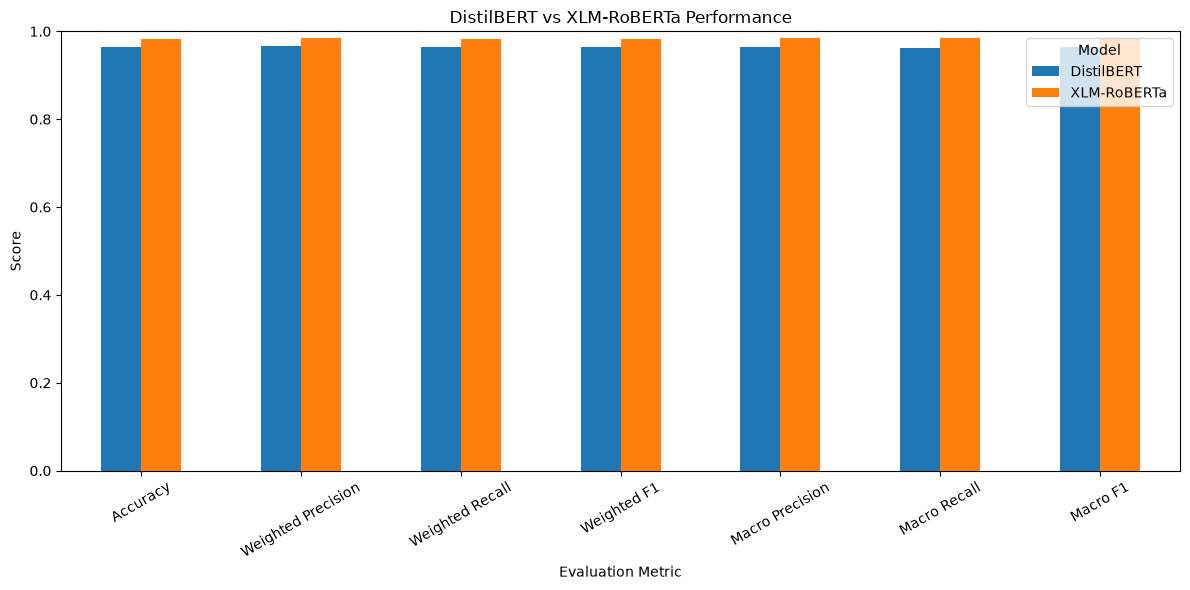

In [34]:
comparison_plot = comparison.set_index(
    "Metric"
)

comparison_plot[
    ["DistilBERT", "XLM-RoBERTa"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "DistilBERT vs XLM-RoBERTa Performance"
)

plt.xlabel("Evaluation Metric")

plt.ylabel("Score")

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=30
)

plt.legend(
    title="Model"
)

plt.tight_layout()

plt.show()

In [35]:
print("=" * 80)
print("DISTILBERT CLASSIFICATION REPORT")
print("=" * 80)

distilbert_report = classification_report(
    distilbert_true,
    distilbert_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

print(distilbert_report)

DISTILBERT CLASSIFICATION REPORT
                      precision    recall  f1-score   support

       addtoplaylist     1.0000    0.9570    0.9780        93
      bookrestaurant     1.0000    0.9899    0.9949        99
          getweather     0.9889    0.9889    0.9889        90
           playmusic     0.9432    0.9540    0.9486        87
            ratebook     0.9868    1.0000    0.9934        75
  searchcreativework     0.8958    0.9556    0.9247        90
searchscreeningevent     0.9365    0.8939    0.9147        66

            accuracy                         0.9650       600
           macro avg     0.9645    0.9628    0.9633       600
        weighted avg     0.9658    0.9650    0.9651       600



In [36]:
print("=" * 80)
print("XLM-RoBERTa CLASSIFICATION REPORT")
print("=" * 80)

xlm_report = classification_report(
    xlm_true,
    xlm_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

print(xlm_report)

XLM-RoBERTa CLASSIFICATION REPORT
                      precision    recall  f1-score   support

       addtoplaylist     1.0000    0.9355    0.9667        93
      bookrestaurant     1.0000    0.9899    0.9949        99
          getweather     1.0000    1.0000    1.0000        90
           playmusic     0.9255    1.0000    0.9613        87
            ratebook     0.9868    1.0000    0.9934        75
  searchcreativework     0.9888    0.9778    0.9832        90
searchscreeningevent     0.9848    0.9848    0.9848        66

            accuracy                         0.9833       600
           macro avg     0.9837    0.9840    0.9835       600
        weighted avg     0.9842    0.9833    0.9834       600



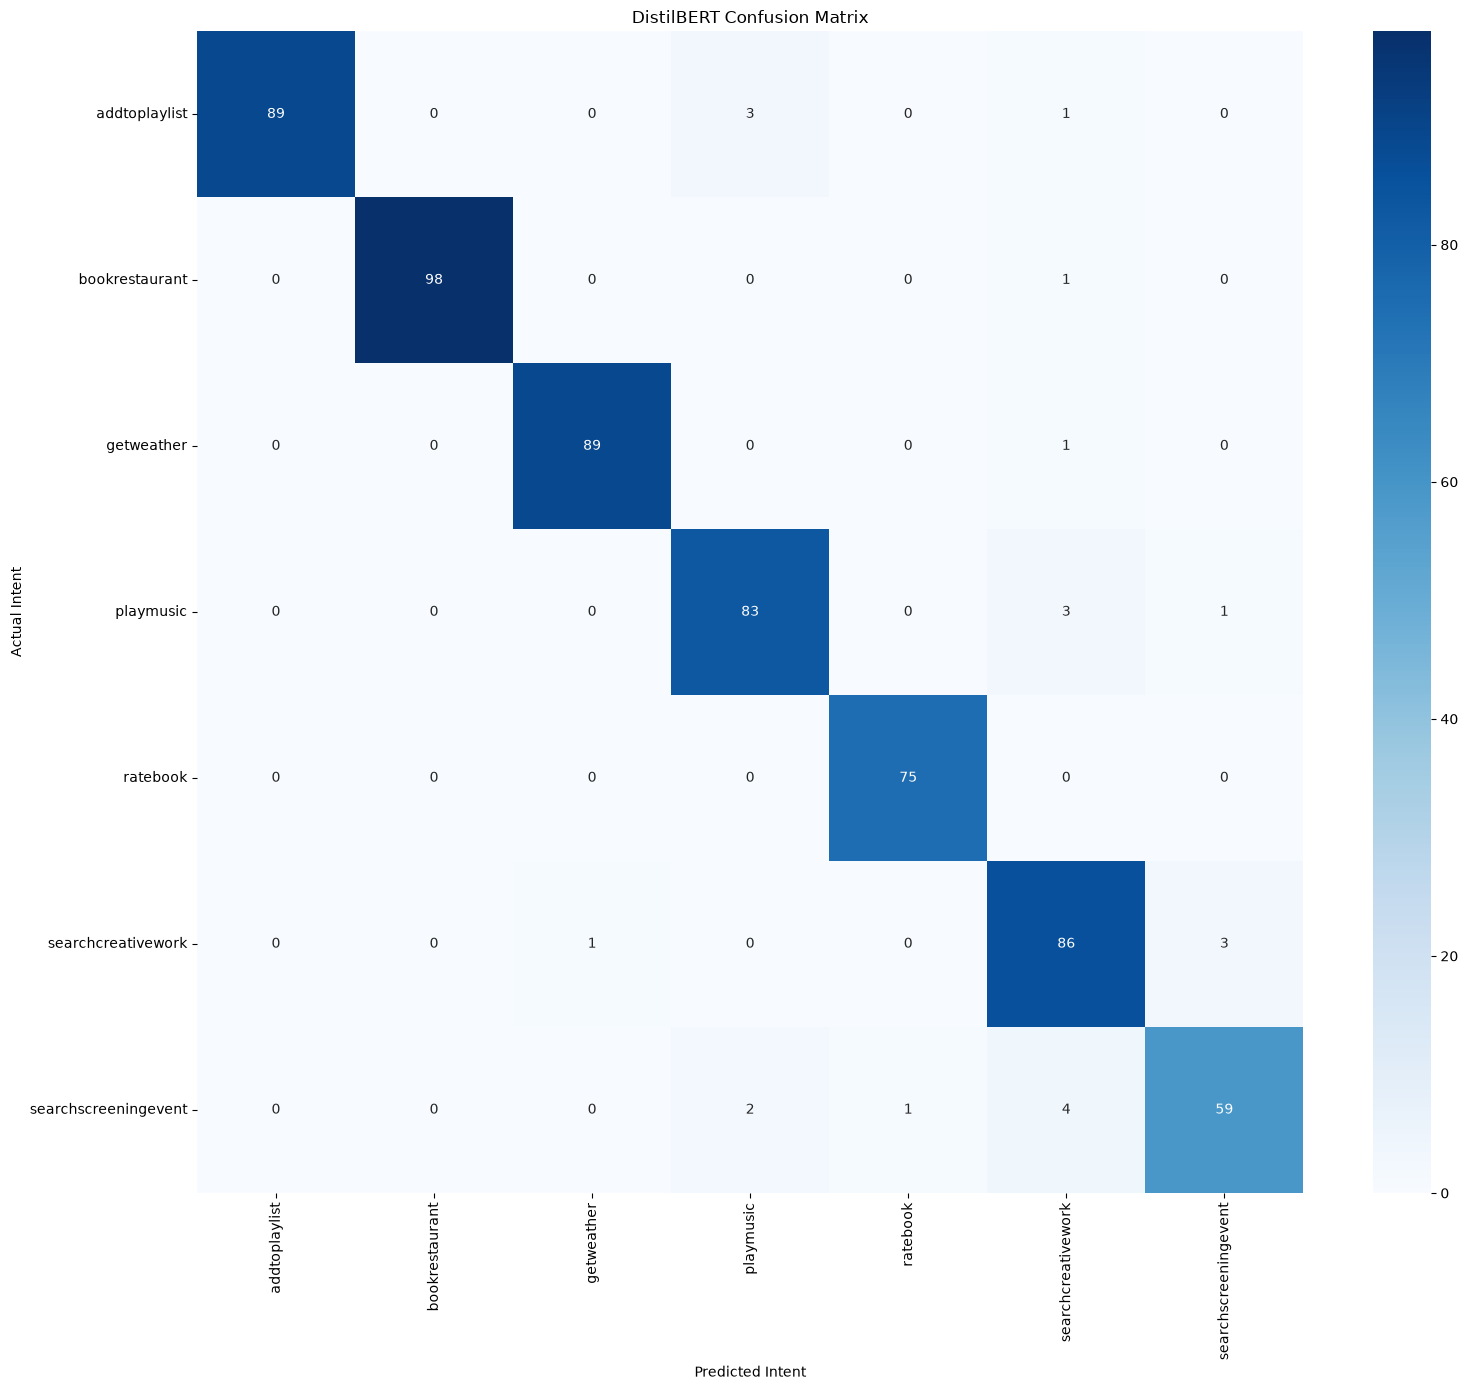

In [37]:
distilbert_cm = confusion_matrix(
    distilbert_true,
    distilbert_pred
)

plt.figure(
    figsize=(16, 14)
)

sns.heatmap(
    distilbert_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.title(
    "DistilBERT Confusion Matrix"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

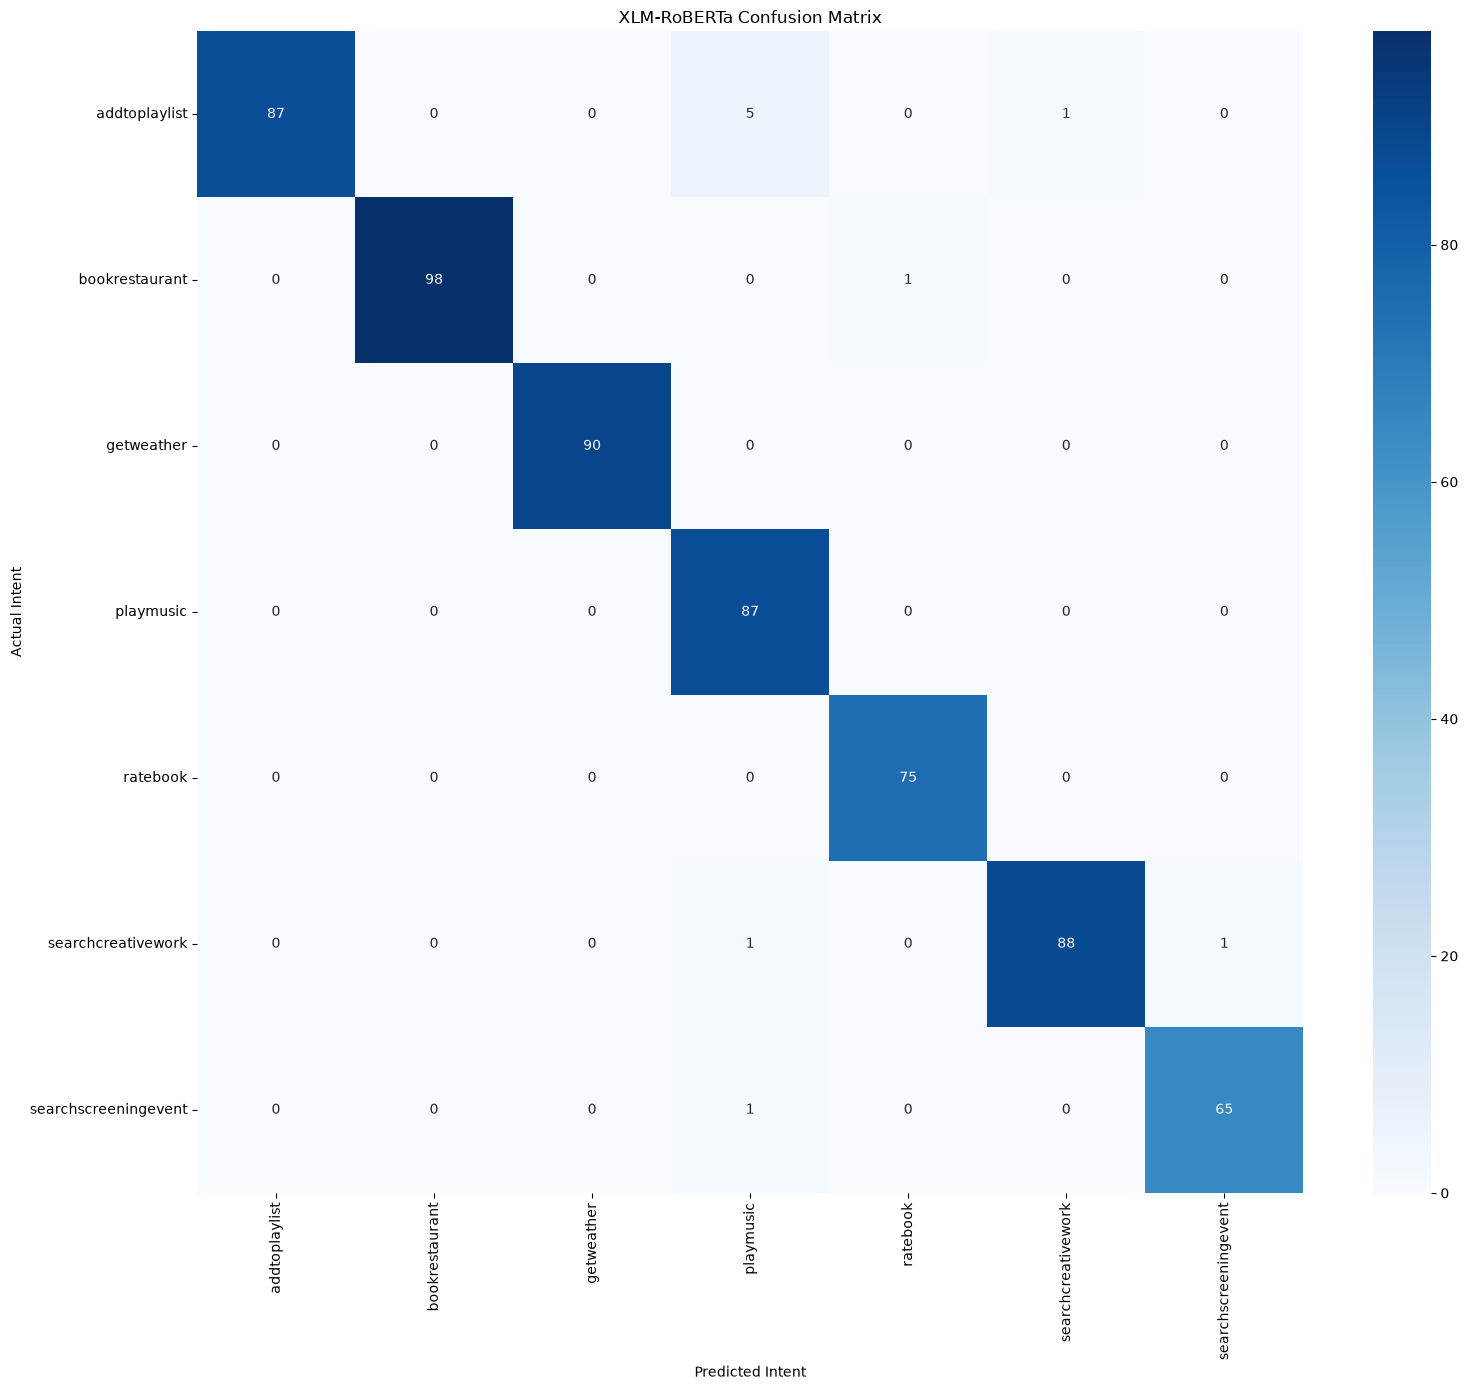

In [38]:
xlm_cm = confusion_matrix(
    xlm_true,
    xlm_pred
)

plt.figure(
    figsize=(16, 14)
)

sns.heatmap(
    xlm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.title(
    "XLM-RoBERTa Confusion Matrix"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [39]:
distilbert_time = (
    distilbert_train_result.metrics.get(
        "train_runtime",
        0
    )
)

xlm_time = (
    xlm_train_result.metrics.get(
        "train_runtime",
        0
    )
)

print("=" * 70)
print("TRAINING TIME COMPARISON")
print("=" * 70)

print(
    f"DistilBERT training time   : "
    f"{distilbert_time:.2f} seconds"
)

print(
    f"XLM-RoBERTa training time  : "
    f"{xlm_time:.2f} seconds"
)

print(
    f"DistilBERT training time   : "
    f"{distilbert_time / 60:.2f} minutes"
)

print(
    f"XLM-RoBERTa training time  : "
    f"{xlm_time / 60:.2f} minutes"
)

TRAINING TIME COMPARISON
DistilBERT training time   : 329.12 seconds
XLM-RoBERTa training time  : 1345.15 seconds
DistilBERT training time   : 5.49 minutes
XLM-RoBERTa training time  : 22.42 minutes


In [40]:
comparison_predictions = test_df[
    [
        "Sentence",
        "Language",
        "Intent"
    ]
].copy()

comparison_predictions[
    "DistilBERT Prediction"
] = [
    label_encoder.inverse_transform(
        [p]
    )[0]
    for p in distilbert_pred
]

comparison_predictions[
    "XLM-RoBERTa Prediction"
] = [
    label_encoder.inverse_transform(
        [p]
    )[0]
    for p in xlm_pred
]

comparison_predictions[
    "DistilBERT Correct"
] = (
    comparison_predictions["Intent"]
    ==
    comparison_predictions["DistilBERT Prediction"]
)

comparison_predictions[
    "XLM-RoBERTa Correct"
] = (
    comparison_predictions["Intent"]
    ==
    comparison_predictions["XLM-RoBERTa Prediction"]
)

display(
    comparison_predictions.head(30)
)

,Sentence,Language,Intent,DistilBERT Prediction,XLM-RoBERTa Prediction,DistilBERT Correct,XLM-RoBERTa Correct
30,I want to hear from Pepe Marchena song Delaware,english,playmusic,playmusic,playmusic,True,True
31,আমি পেপে মারচেনার ডেলাওয়্যার গানটি শুনতে চাই।,bangla,playmusic,playmusic,playmusic,True,True
32,Ami Pepe Marchena er Delaware song ta shunte c...,codemixed,playmusic,playmusic,playmusic,True,True
33,"Will it hail on July 20, 2027 in Ingalls, Malta",english,getweather,getweather,getweather,True,True
34,২০২৭ সালের ২০ জুলাই মাল্টার ইঙ্গলসে কি শিলাবৃষ...,bangla,getweather,getweather,getweather,True,True
35,"July 20, 2027 e Malta er Ingalls e ki hail hobe?",codemixed,getweather,getweather,getweather,True,True
51,Tell me the weather forecast for Island Mountain,english,getweather,getweather,getweather,True,True
52,আইল্যান্ড মাউন্টেনের আবহাওয়ার পূর্বাভাস বলো।,bangla,getweather,getweather,getweather,True,True
53,Island Mountain er weather forecast amake bolo.,codemixed,getweather,getweather,getweather,True,True
78,Can you search the Daring Youth saga?,english,searchcreativework,searchcreativework,searchcreativework,True,True


In [41]:
distilbert_correct = (
    comparison_predictions[
        "DistilBERT Correct"
    ].sum()
)

xlm_correct = (
    comparison_predictions[
        "XLM-RoBERTa Correct"
    ].sum()
)

total_test = len(
    comparison_predictions
)

print("=" * 70)
print("TEST PREDICTION SUMMARY")
print("=" * 70)

print(
    f"Total test samples     : {total_test}"
)

print(
    f"DistilBERT correct      : "
    f"{distilbert_correct}"
)

print(
    f"DistilBERT incorrect    : "
    f"{total_test - distilbert_correct}"
)

print(
    f"XLM-RoBERTa correct     : "
    f"{xlm_correct}"
)

print(
    f"XLM-RoBERTa incorrect   : "
    f"{total_test - xlm_correct}"
)

TEST PREDICTION SUMMARY
Total test samples     : 600
DistilBERT correct      : 579
DistilBERT incorrect    : 21
XLM-RoBERTa correct     : 590
XLM-RoBERTa incorrect   : 10


In [42]:
comparison.to_csv(
    "model_performance_comparison.csv",
    index=False
)

comparison_predictions.to_csv(
    "model_prediction_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print("1. model_performance_comparison.csv")
print("2. model_prediction_comparison.csv")

Saved:
1. model_performance_comparison.csv
2. model_prediction_comparison.csv


In [43]:
# ============================================================
# DATASET STATISTICS
# IEEE-STYLE TABLE
# ============================================================

import pandas as pd

dataset_stats = pd.DataFrame({
    "Dataset": [
        "Total",
        "Training",
        "Validation",
        "Testing"
    ],

    "Number of Samples": [
        len(df),
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

print("=" * 70)
print("DATASET STATISTICS")
print("=" * 70)

display(dataset_stats)

DATASET STATISTICS


,Dataset,Number of Samples
0,Total,3150
1,Training,1908
2,Validation,642
3,Testing,600


In [44]:
# ============================================================
# DETAILED DATASET STATISTICS
# ============================================================

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print(f"Total Samples      : {len(df)}")
print(f"Training Samples   : {len(train_df)}")
print(f"Validation Samples : {len(val_df)}")
print(f"Testing Samples    : {len(test_df)}")

print(f"Number of Intents  : {df['Intent'].nunique()}")
print(f"Number of Languages: {df['Language'].nunique()}")

print("\nLanguages:")
print(df["Language"].value_counts())

print("\nIntent Distribution:")
print(df["Intent"].value_counts())

DATASET INFORMATION
Total Samples      : 3150
Training Samples   : 1908
Validation Samples : 642
Testing Samples    : 600
Number of Intents  : 7
Number of Languages: 3

Languages:
Language
english      1050
bangla       1050
codemixed    1050
Name: count, dtype: int64

Intent Distribution:
Intent
getweather              504
playmusic               477
searchcreativework      471
addtoplaylist           444
bookrestaurant          432
ratebook                432
searchscreeningevent    390
Name: count, dtype: int64


In [45]:
# ============================================================
# LANGUAGE DISTRIBUTION TABLE
# ============================================================

language_table = (
    df["Language"]
    .value_counts()
    .reset_index()
)

language_table.columns = [
    "Language",
    "Number of Samples"
]

language_table["Percentage (%)"] = (
    language_table["Number of Samples"]
    / len(df) * 100
)

language_table["Percentage (%)"] = (
    language_table["Percentage (%)"]
    .round(2)
)

print("=" * 70)
print("LANGUAGE DISTRIBUTION")
print("=" * 70)

display(language_table)

LANGUAGE DISTRIBUTION


,Language,Number of Samples,Percentage (%)
0,english,1050,33.33
1,bangla,1050,33.33
2,codemixed,1050,33.33


In [46]:
# ============================================================
# SAVE DATASET TABLES
# ============================================================

dataset_stats.to_csv(
    "IEEE_Dataset_Statistics.csv",
    index=False
)

language_table.to_csv(
    "IEEE_Language_Distribution.csv",
    index=False
)

print("Dataset tables saved successfully!")

Dataset tables saved successfully!


In [47]:
# ============================================================
# DISTILBERT TEST PREDICTIONS
# ============================================================

distilbert_result = distilbert_trainer.predict(
    distilbert_test
)

distilbert_predictions = np.argmax(
    distilbert_result.predictions,
    axis=-1
)

distilbert_labels = (
    distilbert_result.label_ids
)

print("=" * 70)
print("DISTILBERT TEST PREDICTIONS")
print("=" * 70)

print("Number of test samples:",
      len(distilbert_labels))

print("Predictions generated successfully!")

c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DISTILBERT TEST PREDICTIONS
Number of test samples: 600
Predictions generated successfully!


In [48]:
# ============================================================
# XLM-RoBERTa TEST PREDICTIONS
# ============================================================

xlm_result = xlm_trainer.predict(
    xlm_test
)

xlm_predictions = np.argmax(
    xlm_result.predictions,
    axis=-1
)

xlm_labels = (
    xlm_result.label_ids
)

print("=" * 70)
print("XLM-RoBERTa TEST PREDICTIONS")
print("=" * 70)

print("Number of test samples:",
      len(xlm_labels))

print("Predictions generated successfully!")

c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


XLM-RoBERTa TEST PREDICTIONS
Number of test samples: 600
Predictions generated successfully!


In [49]:
# ============================================================
# DISTILBERT CLASS-WISE METRICS
# ============================================================

from sklearn.metrics import classification_report

distilbert_class_report = classification_report(
    distilbert_labels,
    distilbert_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

distilbert_classwise = pd.DataFrame(
    distilbert_class_report
).transpose()

distilbert_classwise = (
    distilbert_classwise
    .drop(
        ["accuracy", "macro avg", "weighted avg"],
        errors="ignore"
    )
)

distilbert_classwise = (
    distilbert_classwise[
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ]
)

print("=" * 70)
print("DISTILBERT CLASS-WISE METRICS")
print("=" * 70)

display(
    distilbert_classwise.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}"
    })
)

DISTILBERT CLASS-WISE METRICS


,precision,recall,f1-score,support
addtoplaylist,1.0000,0.9570,0.9780,93.000000
bookrestaurant,1.0000,0.9899,0.9949,99.000000
getweather,0.9889,0.9889,0.9889,90.000000
playmusic,0.9432,0.9540,0.9486,87.000000
ratebook,0.9868,1.0000,0.9934,75.000000
searchcreativework,0.8958,0.9556,0.9247,90.000000
searchscreeningevent,0.9365,0.8939,0.9147,66.000000


In [50]:
# ============================================================
# XLM-RoBERTa CLASS-WISE METRICS
# ============================================================

xlm_class_report = classification_report(
    xlm_labels,
    xlm_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

xlm_classwise = pd.DataFrame(
    xlm_class_report
).transpose()

xlm_classwise = (
    xlm_classwise
    .drop(
        ["accuracy", "macro avg", "weighted avg"],
        errors="ignore"
    )
)

xlm_classwise = (
    xlm_classwise[
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ]
)

print("=" * 70)
print("XLM-RoBERTa CLASS-WISE METRICS")
print("=" * 70)

display(
    xlm_classwise.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}"
    })
)

XLM-RoBERTa CLASS-WISE METRICS


,precision,recall,f1-score,support
addtoplaylist,1.0000,0.9355,0.9667,93.000000
bookrestaurant,1.0000,0.9899,0.9949,99.000000
getweather,1.0000,1.0000,1.0000,90.000000
playmusic,0.9255,1.0000,0.9613,87.000000
ratebook,0.9868,1.0000,0.9934,75.000000
searchcreativework,0.9888,0.9778,0.9832,90.000000
searchscreeningevent,0.9848,0.9848,0.9848,66.000000


In [51]:
# ============================================================
# DISTILBERT vs XLM-RoBERTa
# CLASS-WISE F1 COMPARISON
# ============================================================

classwise_comparison = pd.DataFrame({
    "Intent": label_encoder.classes_,

    "DistilBERT Precision":
        distilbert_classwise["precision"].values,

    "DistilBERT Recall":
        distilbert_classwise["recall"].values,

    "DistilBERT F1":
        distilbert_classwise["f1-score"].values,

    "XLM-RoBERTa Precision":
        xlm_classwise["precision"].values,

    "XLM-RoBERTa Recall":
        xlm_classwise["recall"].values,

    "XLM-RoBERTa F1":
        xlm_classwise["f1-score"].values
})

print("=" * 80)
print("CLASS-WISE MODEL COMPARISON")
print("=" * 80)

display(
    classwise_comparison.style.format({
        "DistilBERT Precision": "{:.4f}",
        "DistilBERT Recall": "{:.4f}",
        "DistilBERT F1": "{:.4f}",
        "XLM-RoBERTa Precision": "{:.4f}",
        "XLM-RoBERTa Recall": "{:.4f}",
        "XLM-RoBERTa F1": "{:.4f}"
    })
)

CLASS-WISE MODEL COMPARISON


,Intent,DistilBERT Precision,DistilBERT Recall,DistilBERT F1,XLM-RoBERTa Precision,XLM-RoBERTa Recall,XLM-RoBERTa F1
0,addtoplaylist,1.0000,0.9570,0.9780,1.0000,0.9355,0.9667
1,bookrestaurant,1.0000,0.9899,0.9949,1.0000,0.9899,0.9949
2,getweather,0.9889,0.9889,0.9889,1.0000,1.0000,1.0000
3,playmusic,0.9432,0.9540,0.9486,0.9255,1.0000,0.9613
4,ratebook,0.9868,1.0000,0.9934,0.9868,1.0000,0.9934
5,searchcreativework,0.8958,0.9556,0.9247,0.9888,0.9778,0.9832
6,searchscreeningevent,0.9365,0.8939,0.9147,0.9848,0.9848,0.9848


In [52]:
logging_strategy="epoch"

In [53]:
# ============================================================
# DISTILBERT TRAINING HISTORY
# ============================================================

distilbert_history = (
    distilbert_trainer.state.log_history
)

distilbert_train_epochs = []
distilbert_train_losses = []

distilbert_val_epochs = []
distilbert_val_losses = []

distilbert_val_accuracy = []
distilbert_val_f1 = []

for record in distilbert_history:

    # Training loss
    if (
        "loss" in record
        and "eval_loss" not in record
    ):

        distilbert_train_epochs.append(
            record.get("epoch")
        )

        distilbert_train_losses.append(
            record["loss"]
        )

    # Validation results
    if "eval_loss" in record:

        distilbert_val_epochs.append(
            record.get("epoch")
        )

        distilbert_val_losses.append(
            record["eval_loss"]
        )

        if "eval_accuracy" in record:

            distilbert_val_accuracy.append(
                record["eval_accuracy"]
            )

        if "eval_f1" in record:

            distilbert_val_f1.append(
                record["eval_f1"]
            )

print("=" * 70)
print("DISTILBERT TRAINING HISTORY")
print("=" * 70)

print("Training loss values:",
      distilbert_train_losses)

print("Validation loss values:",
      distilbert_val_losses)

print("Validation accuracy:",
      distilbert_val_accuracy)

print("Validation F1:",
      distilbert_val_f1)

DISTILBERT TRAINING HISTORY
Training loss values: [1.1831223805745443, 0.2674875577290853, 0.09787886142730713]
Validation loss values: [0.46069201827049255, 0.1384536325931549, 0.11007420718669891]
Validation accuracy: [0.926791277258567, 0.9704049844236761, 0.9750778816199377]
Validation F1: [0.9266750083527685, 0.9704946142243809, 0.9751956773664747]


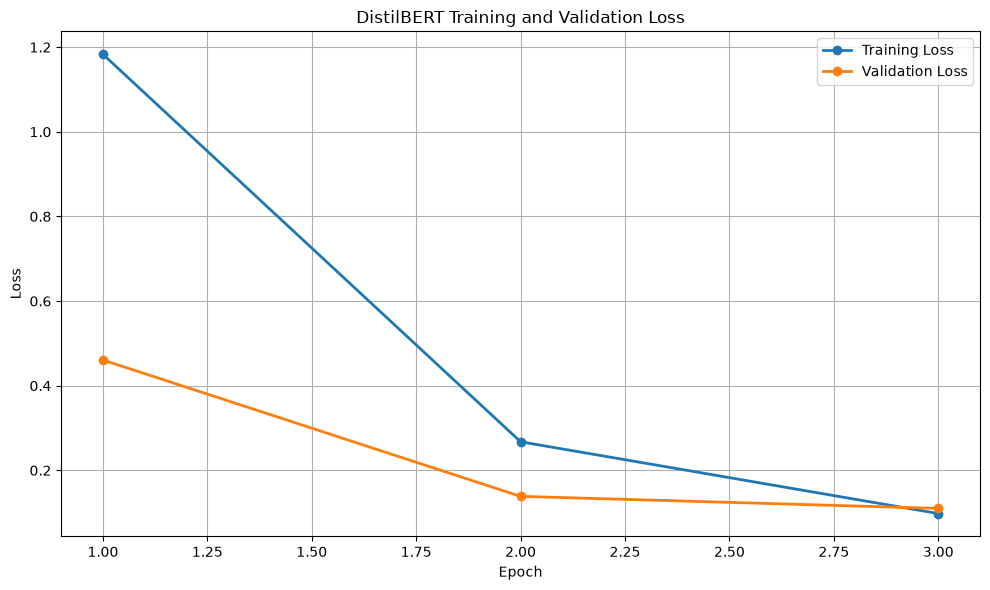

In [54]:
# ============================================================
# DISTILBERT LOSS CURVE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    distilbert_train_epochs,
    distilbert_train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    distilbert_val_epochs,
    distilbert_val_losses,
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "DistilBERT Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

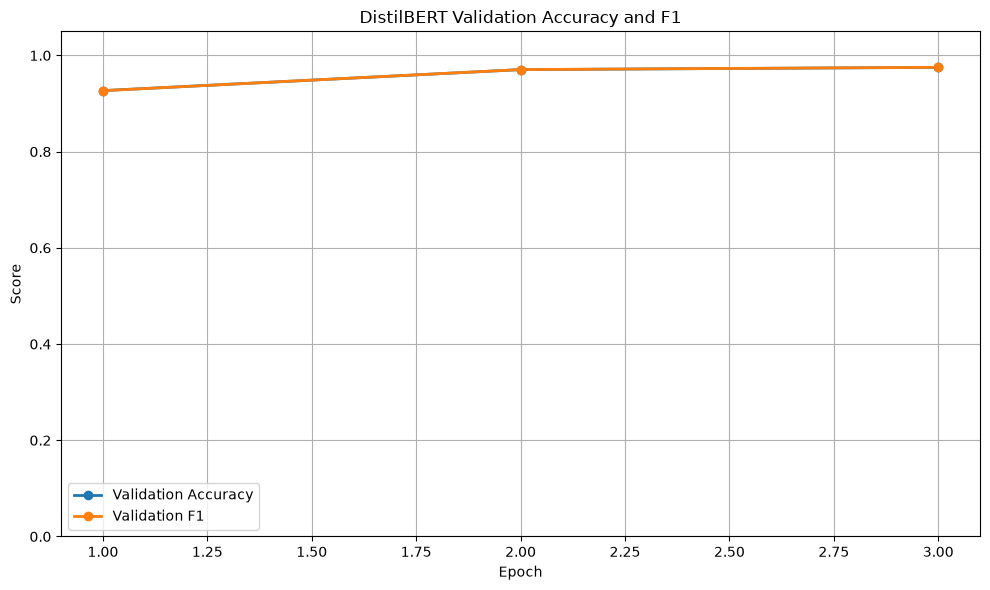

In [55]:
# ============================================================
# DISTILBERT VALIDATION PERFORMANCE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    distilbert_val_epochs,
    distilbert_val_accuracy,
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.plot(
    distilbert_val_epochs,
    distilbert_val_f1,
    marker="o",
    linewidth=2,
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")

plt.title(
    "DistilBERT Validation Accuracy and F1"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [56]:
# ============================================================
# XLM-RoBERTa TRAINING HISTORY
# ============================================================

xlm_history = (
    xlm_trainer.state.log_history
)

xlm_train_epochs = []
xlm_train_losses = []

xlm_val_epochs = []
xlm_val_losses = []

xlm_val_accuracy = []
xlm_val_f1 = []

for record in xlm_history:

    # Training loss
    if (
        "loss" in record
        and "eval_loss" not in record
    ):

        xlm_train_epochs.append(
            record.get("epoch")
        )

        xlm_train_losses.append(
            record["loss"]
        )

    # Validation
    if "eval_loss" in record:

        xlm_val_epochs.append(
            record.get("epoch")
        )

        xlm_val_losses.append(
            record["eval_loss"]
        )

        if "eval_accuracy" in record:

            xlm_val_accuracy.append(
                record["eval_accuracy"]
            )

        if "eval_f1" in record:

            xlm_val_f1.append(
                record["eval_f1"]
            )

print("=" * 70)
print("XLM-RoBERTa TRAINING HISTORY")
print("=" * 70)

print("Training loss:",
      xlm_train_losses)

print("Validation loss:",
      xlm_val_losses)

print("Validation accuracy:",
      xlm_val_accuracy)

print("Validation F1:",
      xlm_val_f1)

XLM-RoBERTa TRAINING HISTORY
Training loss: [0.8094892940760656, 0.07468621800634152, 0.024357107393911195, 0.011268099980374261, 0.010683958500499007]
Validation loss: [0.10719325393438339, 0.05009697005152702, 0.04363271966576576, 0.05592474713921547, 0.05250496417284012]
Validation accuracy: [0.9719626168224299, 0.9890965732087228, 0.9937694704049844, 0.9937694704049844, 0.9937694704049844]
Validation F1: [0.9719125056952163, 0.989125600566611, 0.9937885999529736, 0.9938030458247248, 0.9938030458247248]


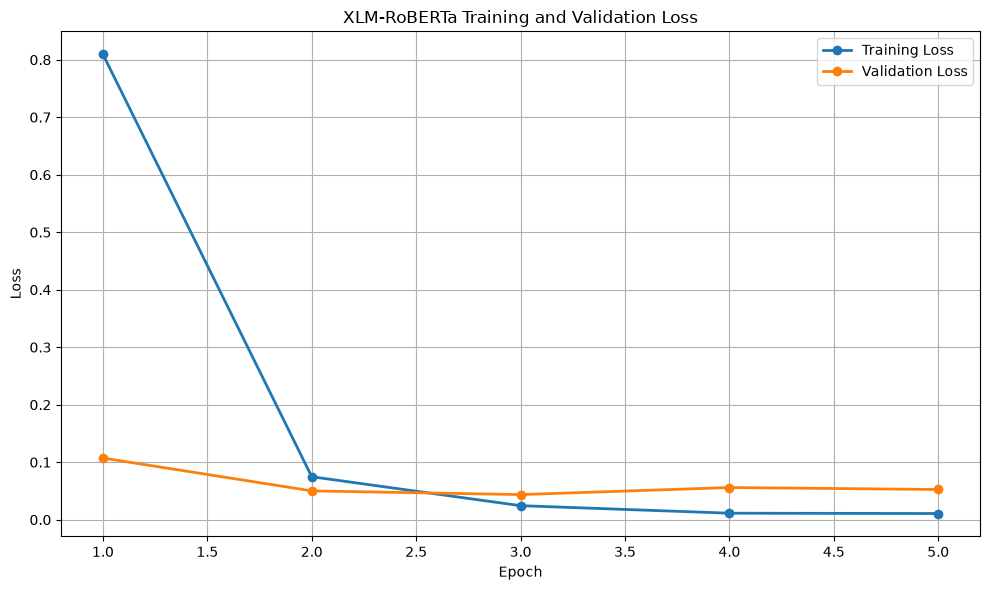

In [57]:
# ============================================================
# XLM-RoBERTa LOSS CURVE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    xlm_train_epochs,
    xlm_train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    xlm_val_epochs,
    xlm_val_losses,
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "XLM-RoBERTa Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

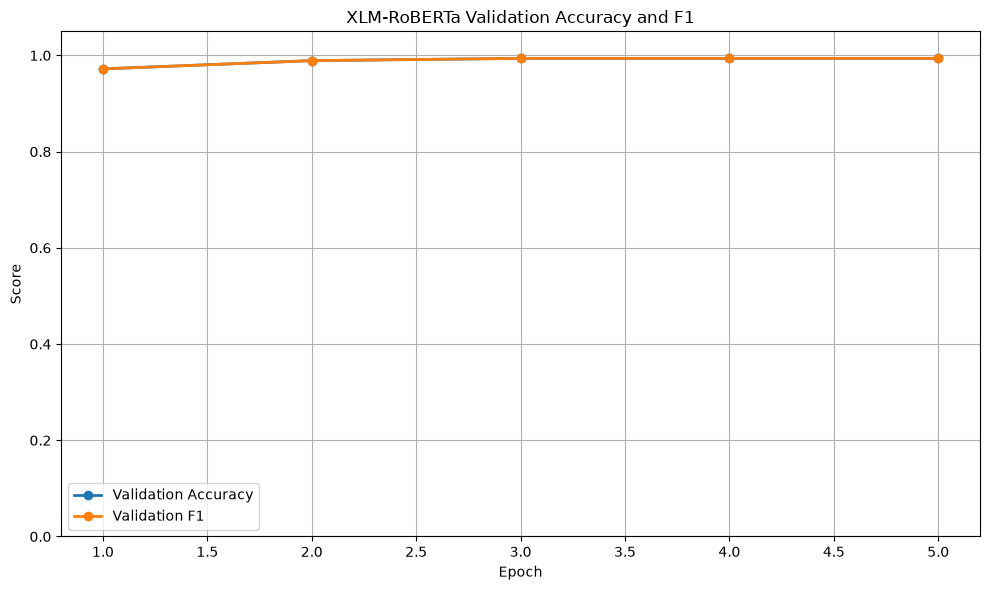

In [58]:
# ============================================================
# XLM-RoBERTa VALIDATION PERFORMANCE
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    xlm_val_epochs,
    xlm_val_accuracy,
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.plot(
    xlm_val_epochs,
    xlm_val_f1,
    marker="o",
    linewidth=2,
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")

plt.title(
    "XLM-RoBERTa Validation Accuracy and F1"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [61]:
# ============================================================
# FINAL IEEE PERFORMANCE TABLE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# -----------------------------
# DistilBERT
# -----------------------------

db_accuracy = accuracy_score(
    distilbert_labels,
    distilbert_predictions
)

db_precision, db_recall, db_f1, _ = (
    precision_recall_fscore_support(
        distilbert_labels,
        distilbert_predictions,
        average="weighted",
        zero_division=0
    )
)

# -----------------------------
# XLM-RoBERTa
# -----------------------------

xlm_accuracy = accuracy_score(
    xlm_labels,
    xlm_predictions
)

xlm_precision, xlm_recall, xlm_f1, _ = (
    precision_recall_fscore_support(
        xlm_labels,
        xlm_predictions,
        average="weighted",
        zero_division=0
    )
)

# -----------------------------
# Create IEEE table
# -----------------------------

final_ieee_table = pd.DataFrame({

    "Model": [
        "DistilBERT",
        "XLM-RoBERTa"
    ],

    "Accuracy": [
        db_accuracy,
        xlm_accuracy
    ],

    "Precision": [
        db_precision,
        xlm_precision
    ],

    "Recall": [
        db_recall,
        xlm_recall
    ],

    "F1-Score": [
        db_f1,
        xlm_f1
    ]
})

print("=" * 80)
print("FINAL MODEL PERFORMANCE")
print("=" * 80)

display(
    final_ieee_table.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)

FINAL MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score
0,DistilBERT,0.9650,0.9658,0.9650,0.9651
1,XLM-RoBERTa,0.9833,0.9842,0.9833,0.9834
